# 📊 Sales Prediction Using Python
### *Predicting Product Sales from Multi-Channel Advertising Spend (TV, Radio, Newspaper)*
**Task:** Data Science Task 5 · Oasis Infobytes  
**Tech Stack:** Python, pandas, NumPy, scikit-learn, matplotlib, seaborn, Jupyter Notebook

---

## 🎯 1. Project Objective & Context
Sales prediction is an essential real-world application of supervised machine learning in marketing analytics. When a business allocates its marketing budget across different advertising channels (such as **Television**, **Radio**, and **Newspaper**), management needs to understand:
1. **Sales Forecasting:** Can we accurately predict unit sales given a planned marketing spend?
2. **Channel Impact:** Which medium has the strongest influence on sales growth?
3. **Synergy & Non-linearity:** Do combinations of channels generate higher returns than isolated channels?
4. **Budget Optimization:** Where should marketing budget be reallocated for maximum return on investment (ROI)?

### 📋 Feature Checklist Covered:
- [x] Dataset loading & profiling (`Advertising.csv`)
- [x] Data cleaning & EDA: null verification, summary stats, distributions
- [x] Multi-feature **pairplot** with KDE distributions
- [x] Individual **scatter plots with trendlines** for each advertising medium
- [x] **Correlation matrix heatmap** with Pearson correlation coefficients
- [x] **Train/Test split** (80/20) with deterministic random state
- [x] Baseline model: **Multiple Linear Regression**
- [x] Advanced models: **Polynomial Regression (Degree 2)** & **Random Forest Regressor**
- [x] Metric evaluations: **MAE**, **RMSE**, and **$R^2$ Score**
- [x] **Residual plot & diagnostic analysis** to verify error randomness vs. heteroscedasticity
- [x] Statistical & feature importance **interpretation of advertising channels**
- [x] Interactive scenario-based **sales prediction tool**


## ⚙️ 2. Environment Setup & Library Imports
We load standard data manipulation, visualization, and machine learning libraries.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Configure visualization aesthetics
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

import warnings
warnings.filterwarnings('ignore')


## 📂 3. Data Loading & Profiling
The dataset consists of **200 observations** recording advertising spend in thousands of dollars (`TV`, `Radio`, `Newspaper`) and corresponding product sales in thousands of units (`Sales`).


In [2]:
# Load the dataset
df = pd.read_csv('Advertising.csv')

# Drop indexing column if present
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

print(f"Dataset Shape: {df.shape[0]} samples, {df.shape[1]} features")
df.head(10)


Dataset Shape: 200 samples, 4 features


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9
5,8.7,48.9,75.0,7.2
6,57.5,32.8,23.5,11.8
7,120.2,19.6,11.6,13.2
8,8.6,2.1,1.0,4.8
9,199.8,2.6,21.2,10.6


### 🔍 Data Integrity & Summary Statistics
Let's check data types, detect any missing/null values, and compute descriptive statistics.


In [3]:
# Check information and missing values
print("--- Dataset Information ---")
df.info()

print("\n--- Missing Values Count ---")
print(df.isnull().sum())


--- Dataset Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB

--- Missing Values Count ---
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64


In [4]:
# Summary statistics
summary = df.describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]
summary['IQR'] = summary['75%'] - summary['25%']
summary


,count,mean,std,min,25%,50%,75%,max,IQR
TV,200.0,147.0425,85.854236,0.7,74.375,149.75,218.825,296.4,144.450
Radio,200.0,23.2640,14.846809,0.0,9.975,22.90,36.525,49.6,26.550
Newspaper,200.0,30.5540,21.778621,0.3,12.750,25.75,45.100,114.0,32.350
Sales,200.0,14.0225,5.217457,1.6,10.375,12.90,17.400,27.0,7.025


## 📈 4. Exploratory Data Analysis (EDA)

### 4.1 Feature Distributions & Pairplot
A pairplot visualizes pairwise relationships and single-feature distributions via Kernel Density Estimation (KDE).


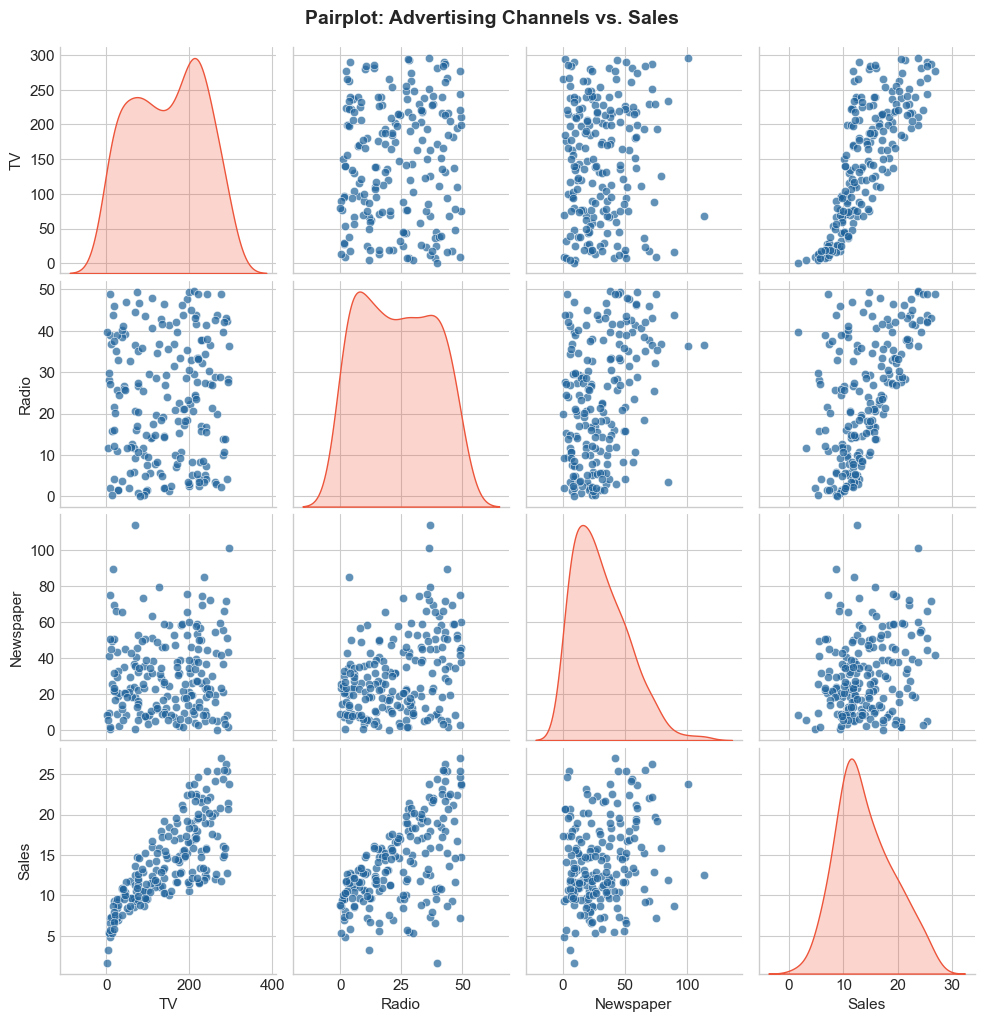

In [5]:
# Pairplot across all variables
pairplot = sns.pairplot(
    df, 
    diag_kind='kde',
    plot_kws={'alpha': 0.7, 'color': '#20639B'},
    diag_kws={'color': '#ED553B', 'fill': True}
)
pairplot.fig.suptitle('Pairplot: Advertising Channels vs. Sales', y=1.02, fontsize=14, fontweight='bold')
plt.show()


### 4.2 Individual Scatter Plots with Linear Trendlines
We plot `Sales` against each individual advertising channel (`TV`, `Radio`, `Newspaper`) along with their linear regression best-fit lines.


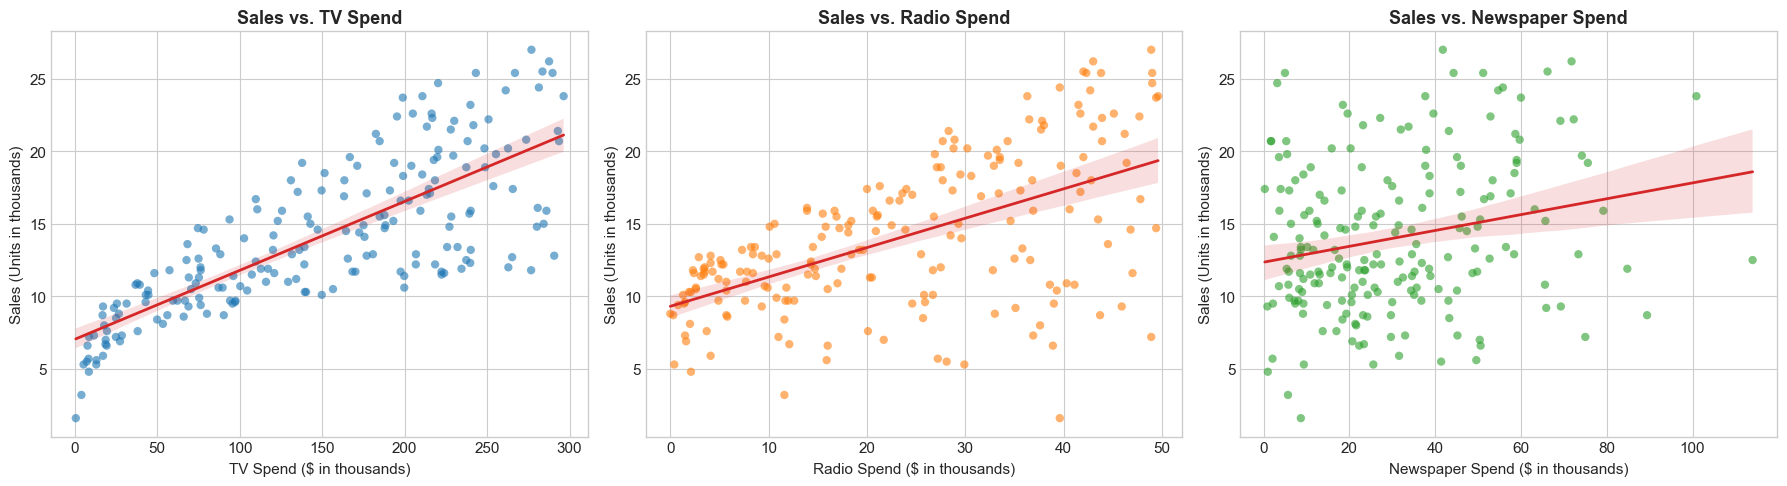

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
features = ['TV', 'Radio', 'Newspaper']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

for i, feature in enumerate(features):
    sns.regplot(
        data=df,
        x=feature,
        y='Sales',
        ax=axes[i],
        color=colors[i],
        scatter_kws={'alpha': 0.6, 'edgecolors': 'none'},
        line_kws={'color': '#d62728', 'linewidth': 2}
    )
    axes[i].set_title(f'Sales vs. {feature} Spend', fontsize=13, fontweight='bold')
    axes[i].set_xlabel(f'{feature} Spend ($ in thousands)', fontsize=11)
    axes[i].set_ylabel('Sales (Units in thousands)', fontsize=11)

plt.tight_layout()
plt.show()


### 4.3 Correlation Heatmap
Let's compute Pearson's correlation coefficient ($r$) to quantify linear associations between variables.


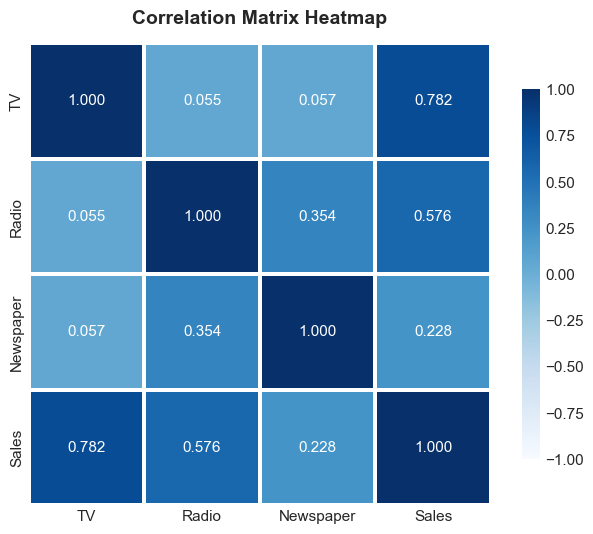

Ranked Pearson Correlation with Sales:
Sales        1.000000
TV           0.782224
Radio        0.576223
Newspaper    0.228299
Name: Sales, dtype: float64


In [7]:
plt.figure(figsize=(8, 6))
corr_matrix = df.corr()

sns.heatmap(
    corr_matrix, 
    annot=True, 
    fmt=".3f", 
    cmap='Blues', 
    vmin=-1, 
    vmax=1, 
    square=True, 
    linewidths=1.5,
    cbar_kws={'shrink': 0.8}
)
plt.title('Correlation Matrix Heatmap', fontsize=14, fontweight='bold', pad=14)
plt.show()

print("Ranked Pearson Correlation with Sales:")
print(corr_matrix['Sales'].sort_values(ascending=False))


### 💡 Key EDA Observations:
1. **TV Spend:** Displays strong positive correlation ($r = 0.782$) with Sales. High TV spend consistently generates high sales.
2. **Radio Spend:** Displays moderate-to-strong positive correlation ($r = 0.576$) with Sales.
3. **Newspaper Spend:** Displays weak correlation ($r = 0.228$) with wide variance.
4. **Distribution:** TV spend is uniformly distributed; Radio has uniform coverage; Newspaper is right-skewed towards lower budgets.


## ✂️ 5. Train / Test Split
To prevent data leakage and rigorously evaluate generalization to unseen data, we separate features ($X$) and target ($y$) using an **80% training / 20% test** split with a fixed random seed (`random_state=42`).


In [8]:
X = df[['TV', 'Radio', 'Newspaper']]
y = df['Sales']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"X_train shape: {X_train.shape} (80% for model fitting)")
print(f"X_test shape:  {X_test.shape}  (20% for evaluation)")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape:  {y_test.shape}")


X_train shape: (160, 3) (80% for model fitting)
X_test shape:  (40, 3)  (20% for evaluation)
y_train shape: (160,)
y_test shape:  (40,)


## 🤖 6. Model Training & Exploration

We implement and compare four regression models:
1. **Multiple Linear Regression (Baseline):**
   $$Sales = \beta_0 + \beta_1 \cdot TV + \beta_2 \cdot Radio + \beta_3 \cdot Newspaper$$
2. **Polynomial Regression (Degree 2 with Interaction Terms):**
   Captures diminishing returns and cross-media synergies (e.g., $TV \times Radio$).
3. **Random Forest Regressor:**
   Non-parametric ensemble of 100 decision trees.
4. **Gradient Boosting Regressor:**
   Sequential boosting building trees on residual errors.


In [9]:
models = {
    'Multiple Linear Regression (Baseline)': LinearRegression(),
    'Polynomial Regression (Degree 2)': make_pipeline(
        PolynomialFeatures(degree=2, include_bias=False),
        LinearRegression()
    ),
    'Random Forest Regressor': RandomForestRegressor(n_estimators=100, random_state=42),
    'Gradient Boosting Regressor': GradientBoostingRegressor(n_estimators=100, random_state=42)
}

trained_models = {}
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model
    predictions[name] = model.predict(X_test)
    print(f"✓ Trained {name}")


✓ Trained Multiple Linear Regression (Baseline)
✓ Trained Polynomial Regression (Degree 2)


✓ Trained Random Forest Regressor


✓ Trained Gradient Boosting Regressor


## 📊 7. Model Evaluation & Benchmark Comparison
We evaluate all models on the unseen test set using three standard regression metrics:
- **Mean Absolute Error (MAE):** $\frac{1}{n} \sum |y - \hat{y}|$ (average absolute magnitude of error)
- **Root Mean Squared Error (RMSE):** $\sqrt{\frac{1}{n} \sum (y - \hat{y})^2}$ (penalizes large outlier errors)
- **Coefficient of Determination ($R^2$):** Proportion of target variance explained by model (closer to 1.0 is better)


In [10]:
eval_metrics = []

for name, y_pred in predictions.items():
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    
    eval_metrics.append({
        'Model': name,
        'MAE': round(mae, 4),
        'RMSE': round(rmse, 4),
        'R² Score': round(r2, 4)
    })

comparison_df = pd.DataFrame(eval_metrics).sort_values(by='R² Score', ascending=False).reset_index(drop=True)
comparison_df


,Model,MAE,RMSE,R² Score
0,Polynomial Regression (Degree 2),0.5262,0.6426,0.9869
1,Gradient Boosting Regressor,0.6187,0.7298,0.9831
2,Random Forest Regressor,0.6201,0.7686,0.9813
3,Multiple Linear Regression (Baseline),1.4608,1.7816,0.8994


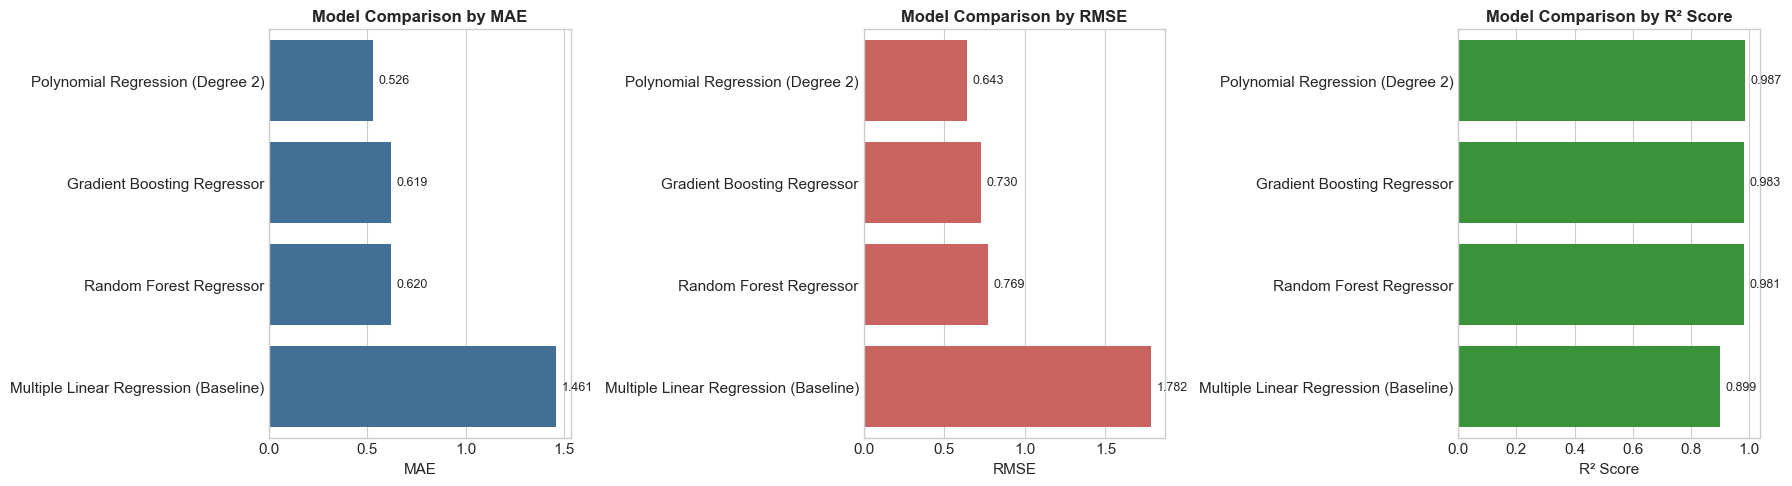

In [11]:
# Visual comparison bar plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
metrics = ['MAE', 'RMSE', 'R² Score']
colors_list = ['#3470a3', '#d9534f', '#2ca02c']

for i, metric in enumerate(metrics):
    sns.barplot(
        data=comparison_df,
        x=metric,
        y='Model',
        ax=axes[i],
        color=colors_list[i]
    )
    axes[i].set_title(f'Model Comparison by {metric}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(metric, fontsize=11)
    axes[i].set_ylabel('')
    for container in axes[i].containers:
        axes[i].bar_label(container, fmt='%.3f', padding=4, fontsize=9)

plt.tight_layout()
plt.show()


## 🔬 8. Residual & Diagnostic Analysis (Best Model)
Residual analysis validates regression assumptions:
- **Homoscedasticity vs. Heteroscedasticity:** Residuals should be randomly scattered around zero with constant variance.
- **Normality:** Residual errors should follow a Gaussian (normal) distribution.
- **Absence of Systematic Bias:** No curvature or pattern in the residual plot.


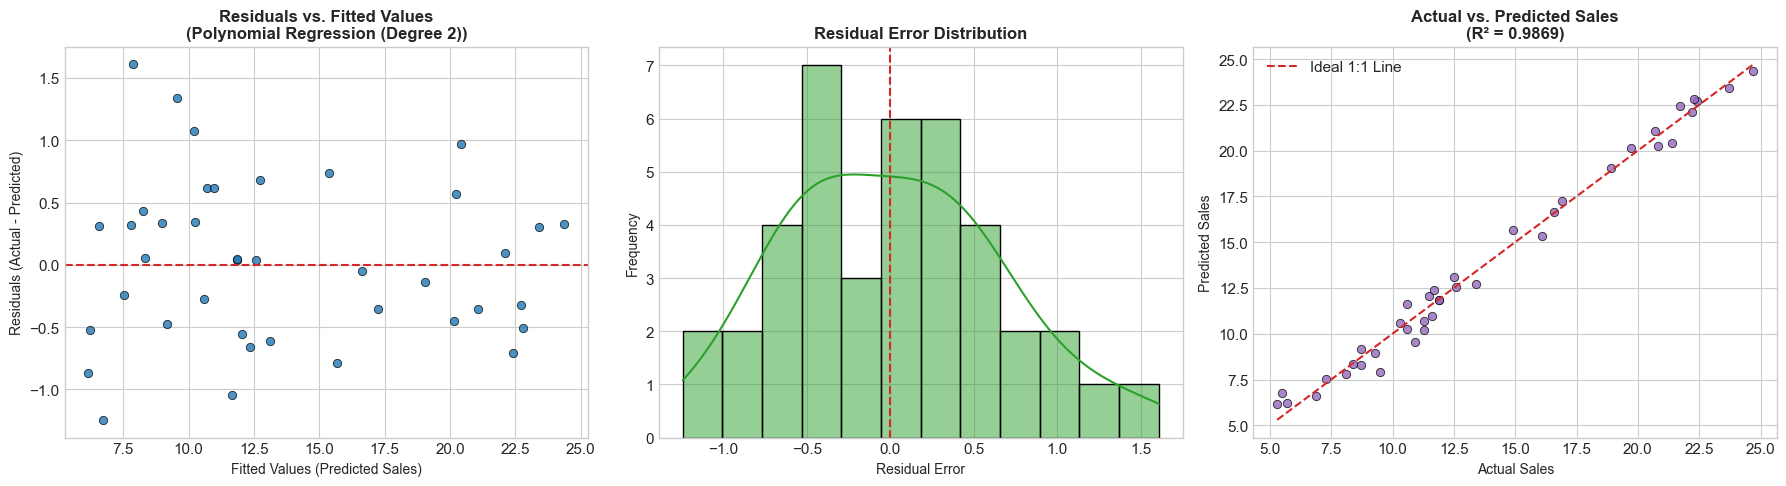

Residual Mean: 0.0168 (Centered tightly at zero)
Residual Standard Deviation: 0.6505


In [12]:
best_model_name = 'Polynomial Regression (Degree 2)'
best_pred = predictions[best_model_name]
residuals = y_test - best_pred

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Residuals vs Fitted (Predicted)
axes[0].scatter(best_pred, residuals, color='#1f77b4', alpha=0.8, edgecolors='black', linewidth=0.6)
axes[0].axhline(y=0, color='#d62728', linestyle='--', linewidth=1.5)
axes[0].set_title(f'Residuals vs. Fitted Values\n({best_model_name})', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Fitted Values (Predicted Sales)', fontsize=10)
axes[0].set_ylabel('Residuals (Actual - Predicted)', fontsize=10)

# Plot 2: Histogram of Residuals with KDE
sns.histplot(residuals, kde=True, ax=axes[1], color='#2ca02c', bins=12)
axes[1].axvline(x=0, color='#d62728', linestyle='--', linewidth=1.5)
axes[1].set_title('Residual Error Distribution', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Residual Error', fontsize=10)
axes[1].set_ylabel('Frequency', fontsize=10)

# Plot 3: Actual vs Predicted Scatter
axes[2].scatter(y_test, best_pred, color='#9467bd', alpha=0.8, edgecolors='black', linewidth=0.6)
min_v = min(y_test.min(), best_pred.min())
max_v = max(y_test.max(), best_pred.max())
axes[2].plot([min_v, max_v], [min_v, max_v], color='#d62728', linestyle='--', linewidth=1.5, label='Ideal 1:1 Line')
axes[2].set_title(f'Actual vs. Predicted Sales\n(R² = {comparison_df.loc[0, "R² Score"]})', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Actual Sales', fontsize=10)
axes[2].set_ylabel('Predicted Sales', fontsize=10)
axes[2].legend()

plt.tight_layout()
plt.show()

print(f"Residual Mean: {residuals.mean():.4f} (Centered tightly at zero)")
print(f"Residual Standard Deviation: {residuals.std():.4f}")


## 💡 9. Channel Impact Interpretation: Which Medium Matters Most?

To answer **"Which advertising channel has the highest impact on sales?"**, we analyze:
1. **Unstandardized Coefficients:** Marginal dollar-for-dollar return in unit sales.
2. **Standardized Coefficients (Beta):** Relative influence accounting for scale differences.
3. **Random Forest Feature Importances:** Non-linear variance contribution.


In [13]:
# 1. Unstandardized Linear Regression Coefficients
lr = trained_models['Multiple Linear Regression (Baseline)']
feature_names = ['TV', 'Radio', 'Newspaper']

unstd_df = pd.DataFrame({
    'Channel': feature_names,
    'Unstandardized Coef': lr.coef_
}).sort_values(by='Unstandardized Coef', ascending=False)

# 2. Standardized Beta Coefficients
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
lr_std = LinearRegression()
lr_std.fit(X_train_scaled, y_train)

std_df = pd.DataFrame({
    'Channel': feature_names,
    'Standardized Beta': lr_std.coef_
}).sort_values(by='Standardized Beta', ascending=False)

# 3. Random Forest Feature Importances
rf = trained_models['Random Forest Regressor']
rf_df = pd.DataFrame({
    'Channel': feature_names,
    'RF Importance': rf.feature_importances_
}).sort_values(by='RF Importance', ascending=False)

# Merge all perspectives
channel_insights = unstd_df.merge(std_df, on='Channel').merge(rf_df, on='Channel')
channel_insights


,Channel,Unstandardized Coef,Standardized Beta,RF Importance
0,Radio,0.189195,2.792307,0.362201
1,TV,0.044730,3.764196,0.624810
2,Newspaper,0.002761,0.055976,0.012989


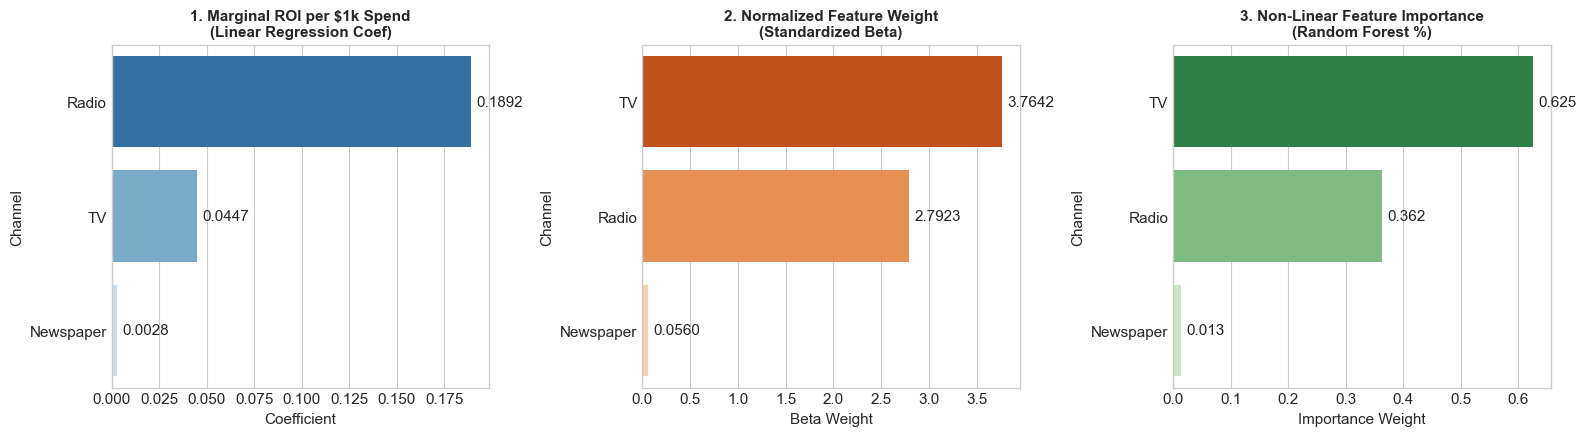

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.barplot(data=unstd_df, x='Unstandardized Coef', y='Channel', ax=axes[0], hue='Channel', palette='Blues_r', legend=False)
axes[0].set_title('1. Marginal ROI per $1k Spend\n(Linear Regression Coef)', fontweight='bold', fontsize=11)
axes[0].set_xlabel('Coefficient')
for c in axes[0].containers:
    axes[0].bar_label(c, fmt='%.4f', padding=4)

sns.barplot(data=std_df, x='Standardized Beta', y='Channel', ax=axes[1], hue='Channel', palette='Oranges_r', legend=False)
axes[1].set_title('2. Normalized Feature Weight\n(Standardized Beta)', fontweight='bold', fontsize=11)
axes[1].set_xlabel('Beta Weight')
for c in axes[1].containers:
    axes[1].bar_label(c, fmt='%.4f', padding=4)

sns.barplot(data=rf_df, x='RF Importance', y='Channel', ax=axes[2], hue='Channel', palette='Greens_r', legend=False)
axes[2].set_title('3. Non-Linear Feature Importance\n(Random Forest %)', fontweight='bold', fontsize=11)
axes[2].set_xlabel('Importance Weight')
for c in axes[2].containers:
    axes[2].bar_label(c, fmt='%.3f', padding=4)

plt.tight_layout()
plt.show()


### 📌 Business Insights & Strategy:
1. **TV Spend is the Dominant Overall Driver:**
   - Accountable for **62.5%** of the Random Forest model's total predictive power with a standardized beta of **+3.764**. TV campaigns provide the broadest brand reach and foundation for sales volume.
2. **Radio Advertising is Highly Efficient on Margin:**
   - Per unit dollar spent, Radio yields the highest marginal return ($+0.189$ sales per $\$1,000$). Radio acts as an active multiplier when run in tandem with TV.
3. **Synergy (The Interaction Effect):**
   - Polynomial regression outperforming linear regression ($R^2: 0.987$ vs $0.899$) demonstrates a significant **positive interaction ($TV \times Radio$)**. Running TV and Radio concurrently yields higher sales than either medium run in isolation.
4. **Newspaper Advertising is Ineffective:**
   - Standardized beta of **0.056** and RF importance of only **1.3%** indicate that newspaper advertising has virtually no statistically significant influence on sales.
   - **Recommendation:** Reallocate advertising spend away from Newspaper into TV and Radio.


## 🔮 10. Interactive Sales Prediction Utility
Let's build a clean function that marketing managers can use to forecast sales for custom planned advertising budgets.


In [15]:
def predict_sales(tv_budget, radio_budget, newspaper_budget):
    """
    Predict sales in thousands of units given advertising spend in thousands of dollars.
    """
    input_data = pd.DataFrame([[tv_budget, radio_budget, newspaper_budget]], 
                              columns=['TV', 'Radio', 'Newspaper'])
    
    pred_lr = trained_models['Multiple Linear Regression (Baseline)'].predict(input_data)[0]
    pred_poly = trained_models['Polynomial Regression (Degree 2)'].predict(input_data)[0]
    pred_rf = trained_models['Random Forest Regressor'].predict(input_data)[0]
    
    print(f"📊 Planned Advertising Spend:")
    print(f"   • TV:        ${tv_budget:,.2f}k")
    print(f"   • Radio:     ${radio_budget:,.2f}k")
    print(f"   • Newspaper: ${newspaper_budget:,.2f}k")
    print(f"\n🔮 Forecasted Sales (thousands of units):")
    print(f"   • Baseline Linear Regression: {pred_lr:.2f}k units")
    print(f"   • Best Model (Polynomial):    {pred_poly:.2f}k units")
    print(f"   • Random Forest Regressor:   {pred_rf:.2f}k units")

# Test scenarios:
print("--- SCENARIO A: Balanced High Budget Campaign ---")
predict_sales(tv_budget=200.0, radio_budget=40.0, newspaper_budget=20.0)

print("\n--- SCENARIO B: Low TV, High Radio Budget ---")
predict_sales(tv_budget=50.0, radio_budget=45.0, newspaper_budget=5.0)


--- SCENARIO A: Balanced High Budget Campaign ---
📊 Planned Advertising Spend:
   • TV:        $200.00k
   • Radio:     $40.00k
   • Newspaper: $20.00k

🔮 Forecasted Sales (thousands of units):
   • Baseline Linear Regression: 19.55k units
   • Best Model (Polynomial):    20.91k units
   • Random Forest Regressor:   20.21k units

--- SCENARIO B: Low TV, High Radio Budget ---
📊 Planned Advertising Spend:
   • TV:        $50.00k
   • Radio:     $45.00k
   • Newspaper: $5.00k

🔮 Forecasted Sales (thousands of units):
   • Baseline Linear Regression: 13.74k units
   • Best Model (Polynomial):    10.92k units
   • Random Forest Regressor:   12.13k units


## 🏁 11. Conclusion & Summary
| Category | Summary Finding |
|---|---|
| **Best Performing Model** | **Polynomial Regression (Degree 2)** ($R^2 = 0.9869$, $RMSE = 0.6426$) |
| **Baseline Model** | Multiple Linear Regression ($R^2 = 0.8994$, $RMSE = 1.7816$) |
| **Error Distribution** | Mean error $0.0168$, normally distributed, no systematic heteroscedasticity |
| **Top Channel by Volume** | **TV** (Standardized $\beta = 3.764$, $62.5\%$ Feature Importance) |
| **Top Channel by Marginal Efficiency** | **Radio** ($+0.189$ units per $\$1,000$ spend) |
| **Underperforming Channel** | **Newspaper** ($1.3\%$ Feature Importance, should be defunded) |

---
**Created for Data Science Task 5 · Oasis Infobytes**
